Generate word clouds for positive and negative reviews by weighting words based on TF-IDF scores instead of simple frequency counts, removing neutral terms dynamically, and enhancing visualization with bigram and trigram analysis.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_excel("Womens Clothing Reviews Data.xlsx")
df.head(5)

,Product ID,Category,Subcategory1,SubCategory2,Location,Channel,Customer Age,Review Title,Review Text,Rating,Recommend Flag
0,767,Initmates,Intimate,Intimates,Mumbai,Mobile,33,NaN,Absolutely wonderful - silky and sexy and comfortable,4,1
1,1080,General,Dresses,Dresses,Bangalore,Mobile,34,NaN,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite. i bought a petite and am 5'8"". i love the length on me- hits just a little below the knee. would definitely be a true midi on someone who is truly petite.",5,1
2,1077,General,Dresses,Dresses,Gurgaon,Mobile,60,Some major design flaws,"I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so small in fact that i could not zip it up! i reordered it in petite medium, which was just ok. overall, the top half was comfortable and fit nicely, but the bottom half had a very tight under layer and several somewhat cheap (net) over layers. imo, a major design flaw was the net over layer sewn directly into the zipper - it c",3,0
3,1049,General Petite,Bottoms,Pants,Chennai,Web,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get nothing but great compliments!",5,1
4,847,General,Tops,Blouses,Bangalore,Web,47,Flattering shirt,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length to wear with leggings and it is sleeveless so it pairs well with any cardigan. love this shirt!!!,5,1


In [3]:
print(df.shape)
print(df.columns.tolist())

(23486, 11)
['Product ID', 'Category', 'Subcategory1', 'SubCategory2', 'Location', 'Channel', 'Customer Age', 'Review Title', 'Review Text', 'Rating', 'Recommend Flag']


Sentiment classification

In [4]:
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

In [7]:
nltk.download('vader_lexicon', quiet=True)

sia = SentimentIntensityAnalyzer()

df_wc = df.dropna(subset=['Review Text']).copy()

# Calculate sentiment scores
df_wc['compound'] = df_wc['Review Text'].astype(str).apply(lambda x: sia.polarity_scores(x)['compound'])

df_wc['Sentiment'] = df_wc['compound'].apply(
    lambda x: 'Positive' if x >= 0.05
    else ('Negative' if x <= -0.05 else 'Neutral')
)

print("Sentiment Distribution:")
print(df_wc['Sentiment'].value_counts())

print("\nDataset Shape:", df_wc.shape)

Sentiment Distribution:
Sentiment
Positive    20987
Negative     1375
Neutral       279
Name: count, dtype: int64

Dataset Shape: (22641, 13)


- nltk.download() downloads the VADER sentiment dictionary.
- SentimentIntensityAnalyzer() initializes the sentiment analyzer.
- dropna() removes rows with missing review text.
- astype(str) converts reviews into strings.
- apply() applies sentiment analysis to each review.
- polarity_scores() calculates sentiment scores, and compound extracts the overall score.
- Reviews are classified as Positive (≥ 0.05), Negative (≤ -0.05), or Neutral (between -0.05 and 0.05).
- value_counts() counts reviews in each sentiment category.
- shape displays the final dataset dimensions.

TF-IDF Weighted Word Clouds + N-grams

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud

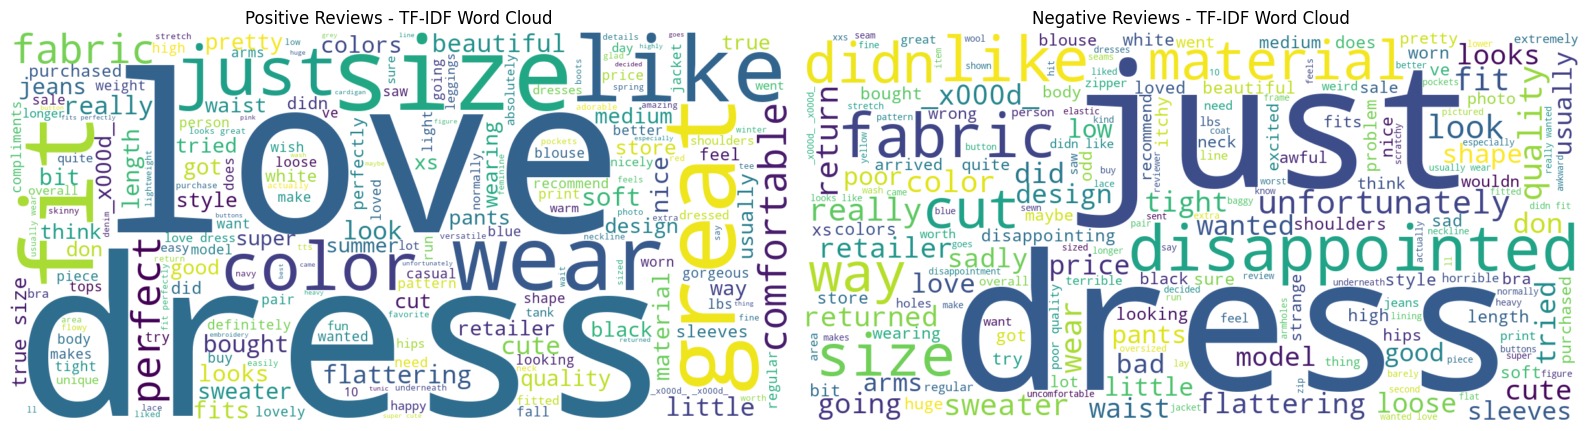

Neutral Terms Removed: 1038
Positive Terms: 3962
Negative Terms: 3050


In [10]:
positive_reviews = df_wc[df_wc['Sentiment'] == 'Positive']['Review Text'].astype(str)
negative_reviews = df_wc[df_wc['Sentiment'] == 'Negative']['Review Text'].astype(str)
neutral_reviews = df_wc[df_wc['Sentiment'] == 'Neutral']['Review Text'].astype(str)

# TF-IDF with unigrams, bigrams and trigrams
vectorizer = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 3),
    min_df=3,
    max_features=5000,
    sublinear_tf=True
)

all_reviews = pd.concat([
    positive_reviews,
    negative_reviews,
    neutral_reviews
])

tfidf_matrix = vectorizer.fit_transform(all_reviews)
feature_names = np.array(vectorizer.get_feature_names_out())

# Split TF-IDF matrices
p = len(positive_reviews)
n = len(negative_reviews)

positive_tfidf = tfidf_matrix[:p]
negative_tfidf = tfidf_matrix[p:p+n]
neutral_tfidf = tfidf_matrix[p+n:]

# Calculate average TF-IDF scores
pos_scores = np.asarray(positive_tfidf.mean(axis=0)).ravel()
neg_scores = np.asarray(negative_tfidf.mean(axis=0)).ravel()
neu_scores = np.asarray(neutral_tfidf.mean(axis=0)).ravel()

# Dynamically identify neutral terms
neutral_mask = (
    (neu_scores > pos_scores) &
    (neu_scores > neg_scores) &
    (neu_scores > 0)
)

neutral_terms = set(feature_names[neutral_mask])

# Remove neutral terms from positive and negative scores
pos_freq = {
    word: score for word, score in zip(feature_names, pos_scores)
    if word not in neutral_terms and score>0
}

neg_freq = {
    word: score for word, score in zip(feature_names, neg_scores)
    if word not in neutral_terms and score > 0
}

# Generate word clouds
positive_wc = WordCloud(
    width=1200,
    height=600,
    background_color='white'
).generate_from_frequencies(pos_freq)

negative_wc = WordCloud(
    width=1200,
    height=600,
    background_color='white'
).generate_from_frequencies(neg_freq)

# Display word clouds
plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
plt.imshow(positive_wc, interpolation='bilinear')
plt.title("Positive Reviews - TF-IDF Word Cloud")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(negative_wc, interpolation='bilinear')
plt.title("Negative Reviews - TF-IDF Word Cloud")
plt.axis('off')

plt.tight_layout()
plt.show()

print("Neutral Terms Removed:", len(neutral_terms))
print("Positive Terms:", len(pos_freq))
print("Negative Terms:", len(neg_freq))

Bigram and Trigram Analysis

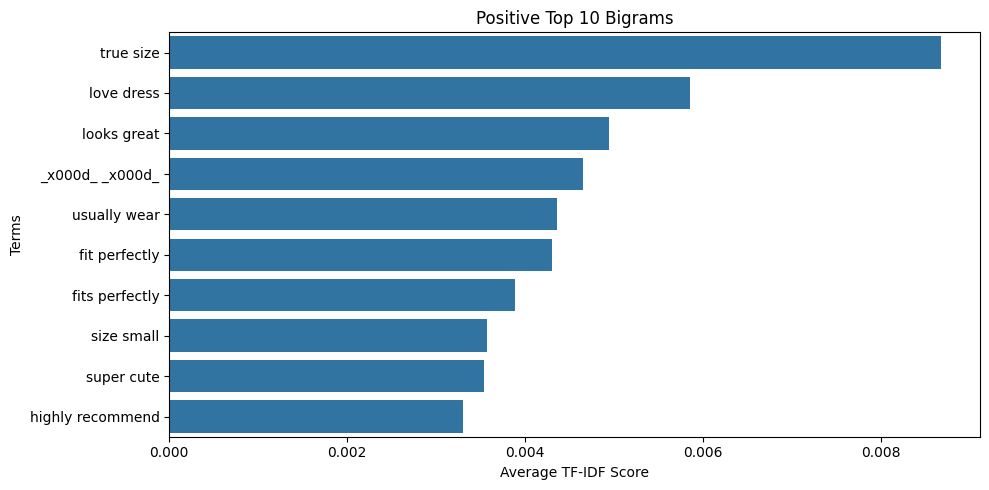

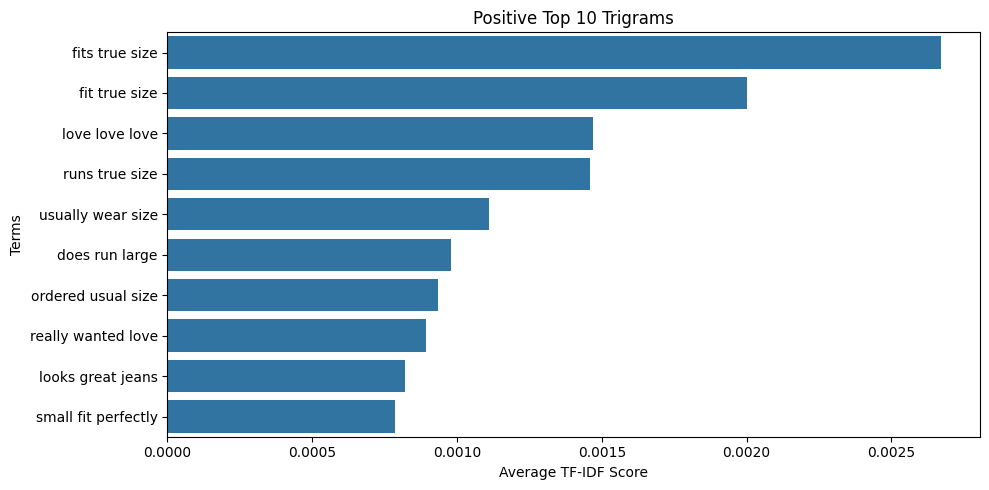

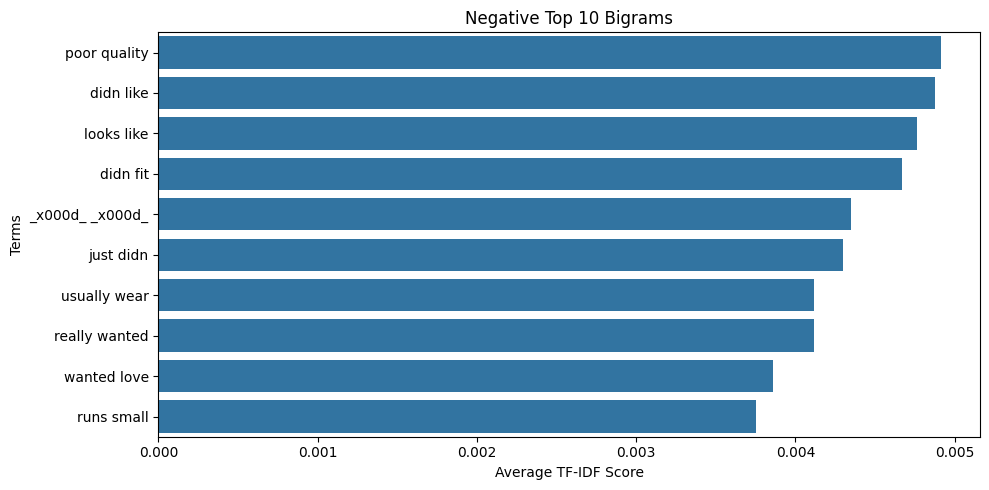

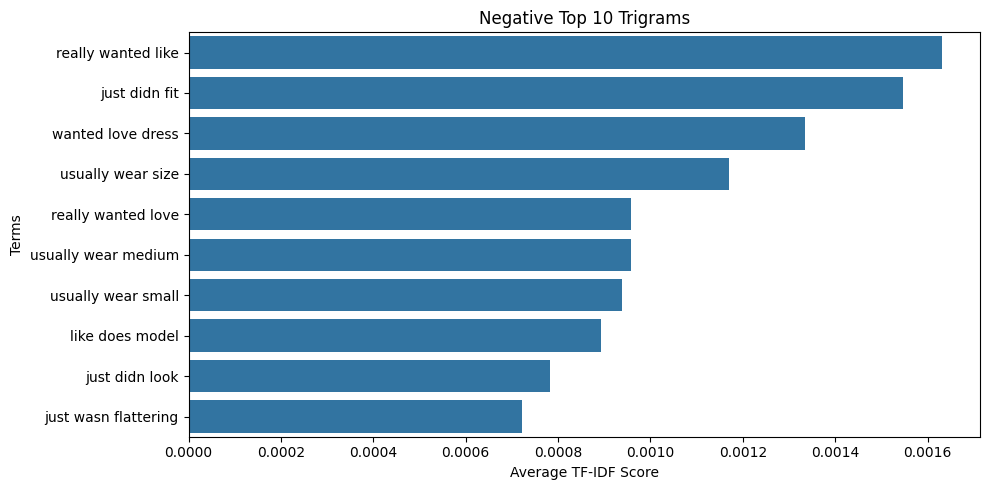

In [12]:
def plot_top_ngrams(scores, feature_names, ngram_size, title):
    indices = [
        i for i, word in enumerate(feature_names)
        if len(word.split())==ngram_size
    ]

    top_indices = sorted(
        indices,
        key=lambda i: scores[i],
        reverse=True
    )[:10]

    words = feature_names[top_indices]
    values = scores[top_indices]

    plt.figure(figsize=(10, 5))
    sns.barplot(x=values, y=words)
    plt.title(title)
    plt.xlabel("Average TF-IDF Score")
    plt.ylabel("Terms")
    plt.tight_layout()
    plt.show()


# Positive bigrams and trigrams
plot_top_ngrams(pos_scores, feature_names, 2, "Positive Top 10 Bigrams")
plot_top_ngrams(pos_scores, feature_names, 3, "Positive Top 10 Trigrams")

# Negative bigrams and trigrams
plot_top_ngrams(neg_scores, feature_names, 2, "Negative Top 10 Bigrams")
plot_top_ngrams(neg_scores, feature_names, 3, "Negative Top 10 Trigrams")

### Conclusion

In this task, sentiment analysis was performed using VADER to classify customer reviews into positive, negative, and neutral categories based on their sentiment scores. The reviews were then analyzed using TF-IDF (Term Frequency–Inverse Document Frequency) to identify important words and phrases rather than relying on simple word-frequency counts. Separate TF-IDF-weighted word clouds were generated for positive and negative reviews, while neutral terms were dynamically identified and removed to highlight sentiment-specific vocabulary.

Additionally, bigram and trigram analysis was performed to identify the top 10 two-word and three-word combinations in positive and negative reviews. The positive reviews mainly highlighted terms related to product size, fitting, appearance, and overall satisfaction, such as love dress, looks great, and fit perfectly. In contrast, negative reviews frequently contained phrases related to poor quality, incorrect fitting, sizing problems, and unmet expectations, such as poor quality, didn fit, and just didn fit.

Overall, this analysis helped identify meaningful patterns in customer feedback, understand the major reasons behind positive and negative shopping experiences, and extract useful insights that can help improve product quality, sizing accuracy, and customer satisfaction.